# Random walks, conservation and diffusion

**Source:** CompSci §§3.1–3.2.1, pp. 15–18 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

A symmetric random walk with step $\ell$ and interval $\Delta t$ has variance $n\ell^2=2Dt$, with $D=\ell^2/(2\Delta t)$. The net flux is down the concentration gradient: $q=-D C_x$. Mass balance on an interval gives $\frac{d}{dt}\int_a^b C\,dx=q(a)-q(b)$, hence $C_t+q_x=0$. For constant $D$ this is $C_t=DC_{xx}$.

On the real line the unit-mass point release gives $C(x,t)=(4\pi Dt)^{-1/2}\exp[-x^2/(4Dt)]$. Write $C=(Dt)^{-1/2}\Phi(x/\sqrt{Dt})$ and substitute to obtain $\Phi''+\frac12(\eta\Phi)'=0$. The decaying zero-flux solution is the Gaussian normalised by unit mass. The Dirac initial condition is a distribution, not an ordinary function with an infinite point value.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


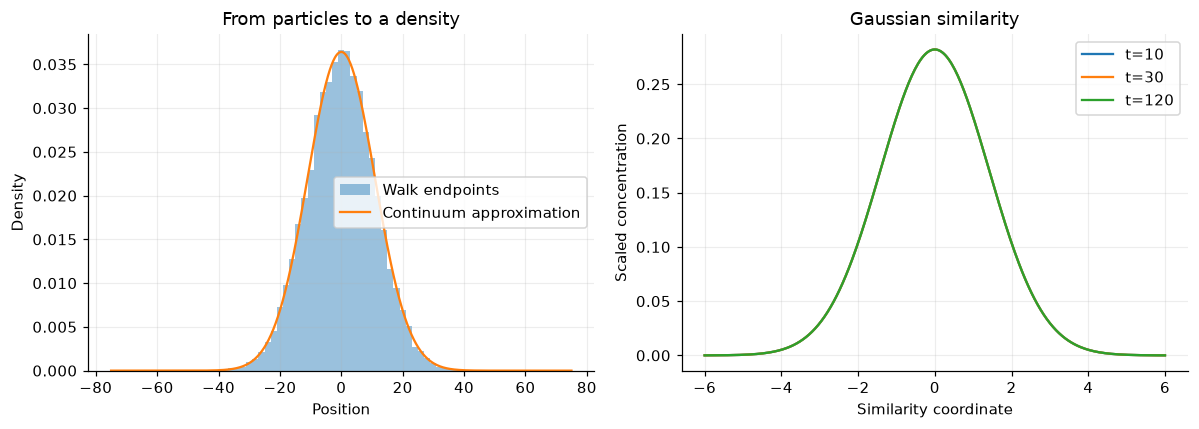

In [2]:
rng=np.random.default_rng(42)
steps=120; walks=30000; D=.5
samples=2*rng.binomial(steps,.5,walks)-steps
x=np.linspace(-75,75,801)
def kernel(x,t):
    return np.exp(-x*x/(4*D*t))/np.sqrt(4*np.pi*D*t)
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].hist(samples,bins=np.arange(-75,77,2),density=True,alpha=.45,label="Walk endpoints")
ax[0].plot(x,kernel(x,steps),label="Continuum approximation")
ax[0].set(xlabel="Position",ylabel="Density",title="From particles to a density"); ax[0].legend()
eta=np.linspace(-6,6,301)
for t in [10,30,120]:
    y=kernel(eta*np.sqrt(D*t),t)*np.sqrt(D*t)
    ax[1].plot(eta,y,label=f"t={t}")
ax[1].set(xlabel="Similarity coordinate",ylabel="Scaled concentration",title="Gaussian similarity"); ax[1].legend()
show(fig,"03-diffusion")
assert abs(np.var(samples)/(2*D*steps)-1)<.035
assert abs(np.trapezoid(kernel(x,steps),x)-1)<1e-8

## Worked exercise

**If time grows fourfold, what happens to plume width and peak?** Width doubles and peak halves, preserving mass. These conclusions assume constant diffusivity and an unbounded domain.

## Additional experiment

Gaussian increments as an alternative to the symmetric lattice walk.

In [3]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})
rng = np.random.default_rng(42)

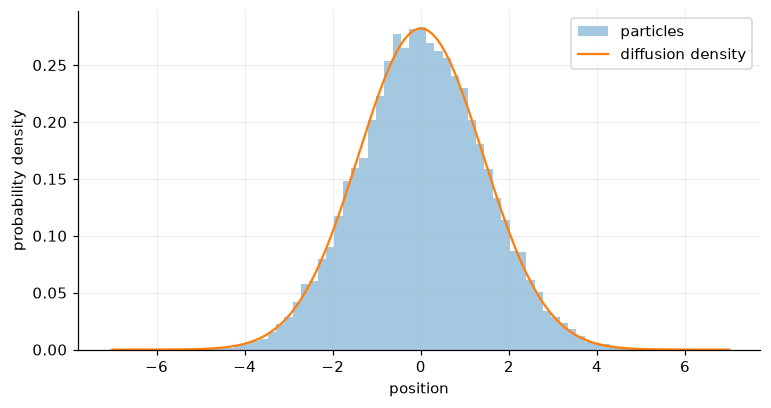

Observed variance / theoretical variance: 1.012409187453807


In [4]:
D=.5;dt=.01;n=200;walkers=20000
x=np.zeros(walkers)
for _ in range(n): x+=rng.normal(0,np.sqrt(2*D*dt),walkers)
t=n*dt;grid=np.linspace(-7,7,500)
p=np.exp(-grid**2/(4*D*t))/np.sqrt(4*np.pi*D*t)
plt.hist(x,bins=70,density=True,alpha=.4,label="particles");plt.plot(grid,p,label="diffusion density")
plt.xlabel("position");plt.ylabel("probability density");plt.legend();plt.show()
print("Observed variance / theoretical variance:",x.var()/(2*D*t))
assert abs(x.var()/(2*D*t)-1)<.05
assert abs(np.trapezoid(p,grid)-1)<.001

## Further practice

Repeat with 500 particles. Compare sampling noise with the deterministic discretisation errors from the previous layer.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.